# NumPy y pandas · Análisis exploratorio de datos

Un análisis exploratorio completo antes de construir cualquier modelo: entender la variable objetivo, ver cómo se relaciona con las demás, tratar los datos ausentes y los atípicos, y comprobar los supuestos de normalidad y homocedasticidad que piden muchas técnicas estadísticas. Se usa el conjunto de datos *Ames Housing* de Dean De Cock, con 2930 ventas de viviendas en Ames (Iowa, EE. UU.) entre 2006 y 2010 y 80 variables descriptivas, publicado en el artículo [«Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project»](https://jse.amstat.org/v19n3/decock.pdf) (*Journal of Statistics Education*, 19(3), 2011), con su [documentación de las variables](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt). Ideas del análisis [*Comprehensive data exploration with Python*](https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python) de Pedro Marcelino y de su [traducción al español](https://www.kaggle.com/code/abonaplata/analisis-exploratorio-de-datos-con-python).

Necesita conexión a internet la primera vez: el fichero se descarga junto al notebook y se reutiliza en las siguientes ejecuciones. Los precios están en dólares y las superficies en pies cuadrados (1 pie² ≈ 0,093 m²).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy import stats

URL = "https://jse.amstat.org/v19n3/decock/AmesHousing.txt"
FICHERO = Path("AmesHousing.txt")

if not FICHERO.exists():
    with requests.Session() as sesion:
        sesion.headers["User-Agent"] = "ejercicios-python/1.0"
        respuesta = sesion.get(URL, timeout=30)
        respuesta.raise_for_status()
        FICHERO.write_bytes(respuesta.content)
print(f"{FICHERO}: {FICHERO.stat().st_size / 1024:.0f} KB")

AmesHousing.txt: 938 KB


## 1. Carga y primer vistazo

Leer el fichero (separado por tabuladores) con `read_csv` y mostrar sus dimensiones y cuántas columnas hay de cada tipo. Renombrar las columnas quitando espacios y barras (`Gr Liv Area` → `GrLivArea`), eliminar la columna `Order`, que solo numera las filas, y usar como índice `PID`, el identificador de la parcela, comprobando antes que no se repite.

In [2]:
casas = pd.read_csv(FICHERO, sep="\t")
print("Dimensiones:", casas.shape)
print(casas.dtypes.value_counts().to_string(), "\n")

casas.columns = casas.columns.str.replace(r"[ /]", "", regex=True)
assert casas["PID"].is_unique
casas = casas.drop(columns="Order").set_index("PID")
print(casas[["Neighborhood", "OverallQual", "YearBuilt", "GrLivArea", "SalePrice"]].head())
print("\nDimensiones finales:", casas.shape)
assert casas.shape == (2930, 80) and not casas.columns.str.contains(" ").any()

Dimensiones: (2930, 82)
str        43
int64      28
float64    11 

          Neighborhood  OverallQual  YearBuilt  GrLivArea  SalePrice
PID                                                                 
526301100        NAmes            6       1960       1656     215000
526350040        NAmes            5       1961        896     105000
526351010        NAmes            6       1958       1329     172000
526353030        NAmes            7       1968       2110     244000
527105010      Gilbert            5       1997       1629     189900

Dimensiones finales: (2930, 80)


## 2. La variable objetivo: el precio de venta

Resumir `SalePrice` con `describe` y medir su forma con la asimetría (`skew`) y la curtosis (`kurt`). Una normal tiene asimetría 0 y curtosis en exceso 0: una asimetría positiva indica una cola larga hacia los precios altos y una curtosis alta, colas más pesadas que las de la normal. Comprobar los valores con `scipy.stats` (pandas usa los estimadores corregidos por sesgo, `bias=False`) y que la media es mayor que la mediana, como corresponde a una cola a la derecha.

In [3]:
precio = casas["SalePrice"]
print(precio.describe().round(0))
asimetria, curtosis = precio.skew(), precio.kurt()
print(f"\nAsimetría: {asimetria:.3f} | curtosis: {curtosis:.3f}")
print(f"Media {precio.mean():,.0f} $ > mediana {precio.median():,.0f} $")

assert np.isclose(asimetria, stats.skew(precio, bias=False))
assert np.isclose(curtosis, stats.kurtosis(precio, bias=False))
assert precio.mean() > precio.median() and precio.min() > 0

count      2930.0
mean     180796.0
std       79887.0
min       12789.0
25%      129500.0
50%      160000.0
75%      213500.0
max      755000.0
Name: SalePrice, dtype: float64

Asimetría: 1.744 | curtosis: 5.119
Media 180,796 $ > mediana 160,000 $


## 3. Histograma con la normal ajustada y gráfico de probabilidad

Dibujar el histograma del precio en densidad junto con la curva de la normal que mejor se ajusta (`stats.norm.fit` estima la media y la desviación) y, al lado, el gráfico de probabilidad normal de `stats.probplot`, que enfrenta los cuantiles de los datos a los de una normal: si los datos fueran normales, los puntos caerían sobre la recta. Guardar el coeficiente de correlación $r$ de ese ajuste para compararlo más adelante.

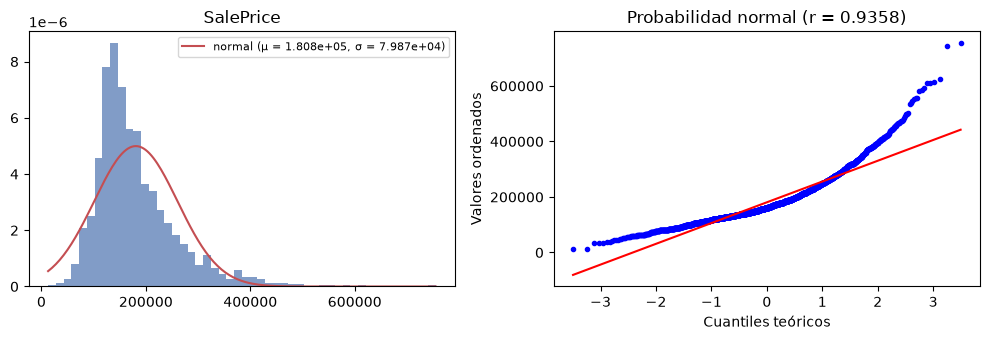

In [4]:
def histograma_y_probabilidad(serie, titulo, ejes):
    mu, sigma = stats.norm.fit(serie)
    ejes[0].hist(serie, bins=50, density=True, color="#4c72b0", alpha=0.7)
    x = np.linspace(serie.min(), serie.max(), 200)
    ejes[0].plot(x, stats.norm.pdf(x, mu, sigma), color="#c44e52", label=f"normal (μ = {mu:.4g}, σ = {sigma:.4g})")
    ejes[0].xaxis.set_major_locator(plt.MaxNLocator(5))
    ejes[0].set_title(titulo)
    ejes[0].legend(fontsize=8)
    (_, _), (_, _, r) = stats.probplot(serie, dist="norm", plot=ejes[1])
    ejes[1].get_lines()[0].set_markersize(3)
    ejes[1].set(title=f"Probabilidad normal (r = {r:.4f})", xlabel="Cuantiles teóricos", ylabel="Valores ordenados")
    return r


fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
r_precio = histograma_y_probabilidad(precio, "SalePrice", ejes)
plt.tight_layout()
plt.show()
assert 0.9 < r_precio < 1

## 4. Relación con variables numéricas y categóricas

Dibujar la dispersión del precio frente a la superficie habitable (`GrLivArea`) y frente a la del sótano (`TotalBsmtSF`) y calcular sus correlaciones. Después, con seaborn, dibujar diagramas de caja del precio según la calidad general (`OverallQual`, de 1 a 10) y según el barrio, con los barrios ordenados por la mediana del precio. Mostrar los tres barrios más caros y los tres más baratos y comprobar que la mediana de la calidad 10 supera a la de la calidad 1.

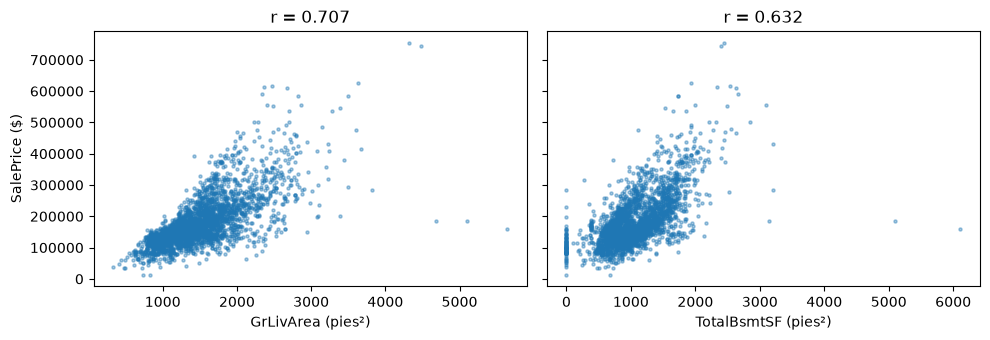

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for eje, columna in zip(ejes, ["GrLivArea", "TotalBsmtSF"]):
    eje.scatter(casas[columna], precio, s=5, alpha=0.4)
    eje.set(xlabel=f"{columna} (pies²)", title=f"r = {casas[columna].corr(precio):.3f}")
ejes[0].set_ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

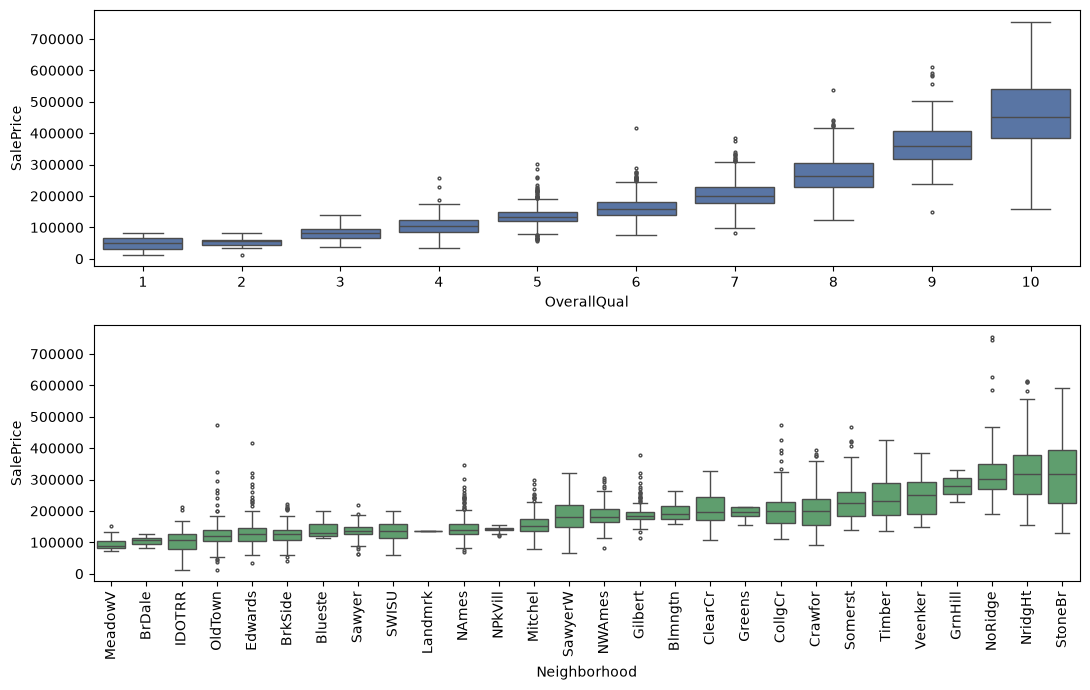

Barrios más baratos: {'MeadowV': 88250.0, 'BrDale': 106000.0, 'IDOTRR': 106500.0}
Barrios más caros: {'NoRidge': 302000.0, 'NridgHt': 317750.0, 'StoneBr': 319000.0}


In [6]:
medianas = casas.groupby("Neighborhood")["SalePrice"].median().sort_values()
fig, ejes = plt.subplots(2, 1, figsize=(11, 7))
sns.boxplot(data=casas, x="OverallQual", y="SalePrice", color="#4c72b0", fliersize=2, ax=ejes[0])
sns.boxplot(data=casas, x="Neighborhood", y="SalePrice", order=medianas.index, color="#55a868", fliersize=2, ax=ejes[1])
ejes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

print("Barrios más baratos:", medianas.head(3).to_dict())
print("Barrios más caros:", medianas.tail(3).to_dict())
por_calidad = casas.groupby("OverallQual")["SalePrice"].median()
assert por_calidad[10] > por_calidad[1] and len(medianas) == casas["Neighborhood"].nunique()

## 5. Matriz de correlación y las variables más correlacionadas

Calcular la matriz de correlación de las columnas numéricas y dibujarla como mapa de calor para ver de un vistazo qué variables se mueven juntas. Elegir con `nlargest` las $k = 10$ variables más correlacionadas con el precio (él incluido) y dibujar su mapa de calor anotado. Buscar en él parejas con correlación mayor que 0,8, que repiten casi la misma información (multicolinealidad).

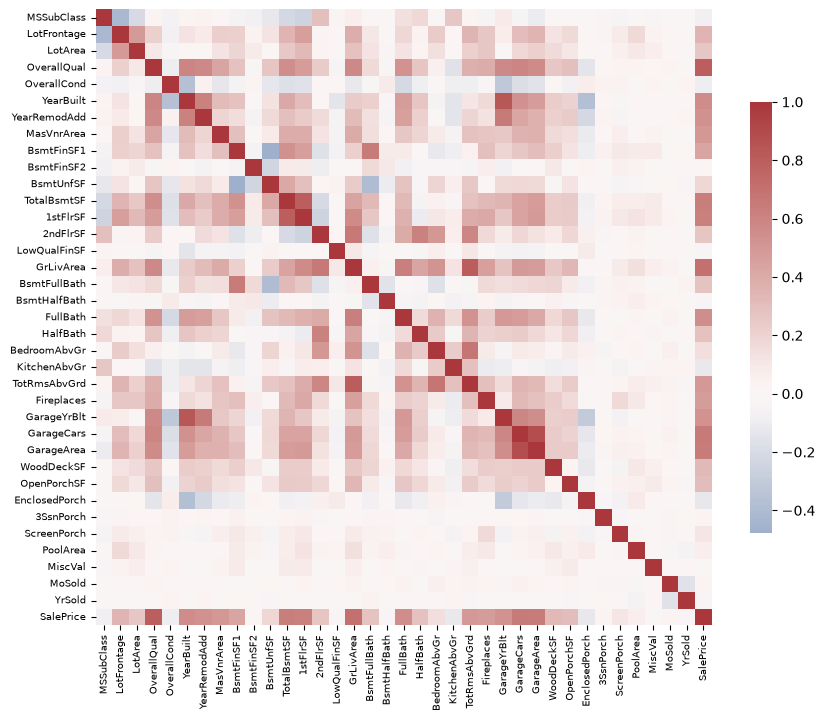

Columnas numéricas: 37


In [7]:
correlacion = casas.select_dtypes("number").corr()
fig, eje = plt.subplots(figsize=(10, 8))
sns.heatmap(correlacion, cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.7}, ax=eje)
eje.tick_params(labelsize=7)
plt.show()
print("Columnas numéricas:", correlacion.shape[0])

SalePrice       1.000
OverallQual     0.799
GrLivArea       0.707
GarageCars      0.648
GarageArea      0.640
TotalBsmtSF     0.632
1stFlrSF        0.622
YearBuilt       0.558
FullBath        0.546
YearRemodAdd    0.533


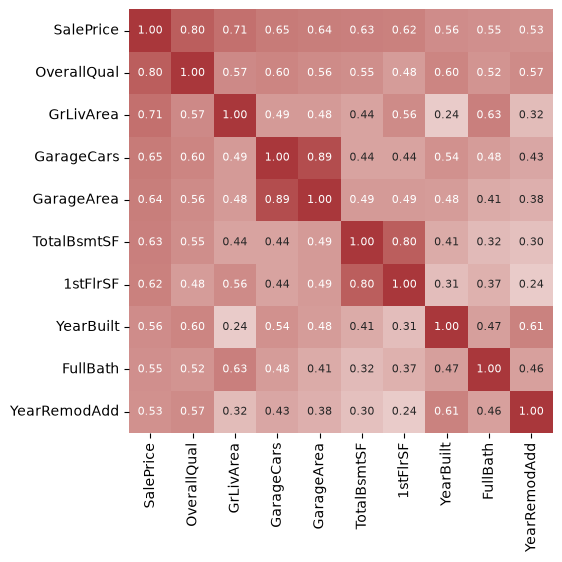

Parejas con r > 0,8: [('GarageCars', 'GarageArea', 0.89), ('TotalBsmtSF', '1stFlrSF', 0.8)]


In [8]:
k = 10
mas_correladas = correlacion["SalePrice"].nlargest(k).index
print(correlacion.loc[mas_correladas, "SalePrice"].round(3).to_string())

fig, eje = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlacion.loc[mas_correladas, mas_correladas], annot=True, fmt=".2f", annot_kws={"size": 8},
            cmap="vlag", center=0, square=True, cbar=False, ax=eje)
plt.show()

sub = correlacion.loc[mas_correladas, mas_correladas]
parejas = [(a, b, sub.loc[a, b]) for i, a in enumerate(mas_correladas) for b in mas_correladas[i + 1:] if sub.loc[a, b] > 0.8]
print("Parejas con r > 0,8:", [(a, b, round(float(r), 2)) for a, b, r in parejas])
assert mas_correladas[0] == "SalePrice" and mas_correladas[1] == "OverallQual"

## 6. Dispersión por parejas con `pairplot`

Dibujar con `sns.pairplot` la matriz de gráficos de dispersión de unas pocas variables relevantes (precio, calidad, superficie habitable, plazas de garaje, superficie del sótano y año de construcción), con histogramas en la diagonal. Para que sea rápido y legible, usar una muestra de 500 casas tomada con una semilla fija.

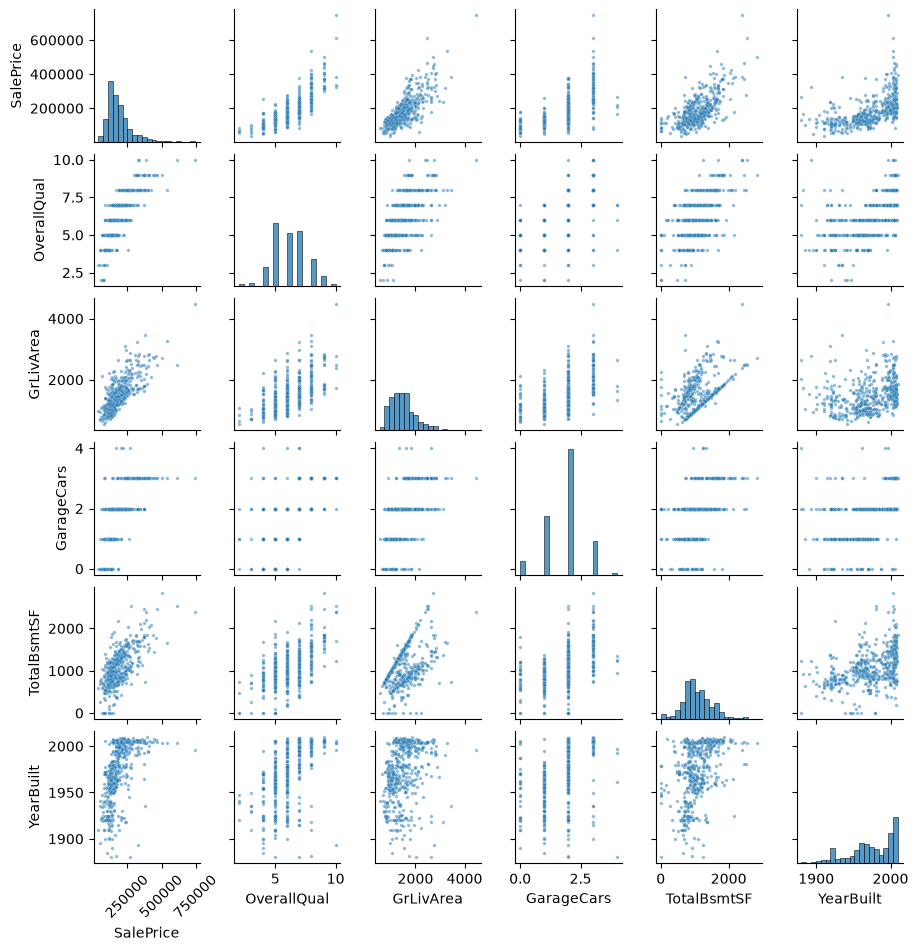

In [9]:
columnas = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt"]
muestra = casas[columnas].dropna().sample(500, random_state=2011)
rejilla = sns.pairplot(muestra, height=1.55, plot_kws={"s": 6, "alpha": 0.5}, diag_kws={"bins": 20})
rejilla.axes[-1, 0].tick_params(axis="x", labelrotation=45)
plt.show()
assert muestra.shape == (500, 6) and muestra.index.is_unique

## 7. Datos ausentes

Contar los valores ausentes de cada columna y su porcentaje. Descartar las columnas con más de un 15 % de ausentes y rellenar el resto de forma razonada según la documentación, donde un ausente suele significar «no tiene»: las categorías de garaje y sótano con `"Ninguno"`, las superficies, baños y plazas con 0, `Electrical` (un solo hueco) con la moda, y eliminar `GarageYrBlt`, que no existe en las casas sin garaje y repite casi lo mismo que `YearBuilt`. Comprobar que no queda ningún ausente.

In [10]:
ausentes = casas.isna().sum()
tabla = pd.DataFrame({"ausentes": ausentes, "porcentaje": ausentes / len(casas) * 100})
tabla = tabla[tabla["ausentes"] > 0].sort_values("ausentes", ascending=False)
print(tabla.round(2).to_string(), "\n")

descartadas = tabla.index[tabla["porcentaje"] > 15].tolist()
print("Se descartan:", descartadas)
print(f"Correlación GarageYrBlt-YearBuilt: {casas['GarageYrBlt'].corr(casas['YearBuilt']):.3f}")

casas = casas.drop(columns=descartadas + ["GarageYrBlt"])
casas["Electrical"] = casas["Electrical"].fillna(casas["Electrical"].mode()[0])
texto = casas.select_dtypes(exclude="number").columns
casas[texto] = casas[texto].fillna("Ninguno")
numericas = casas.select_dtypes("number").columns
casas[numericas] = casas[numericas].fillna(0)

print("\nDimensiones tras limpiar:", casas.shape, "| ausentes:", casas.isna().sum().sum())
print(casas["GarageType"].value_counts().head(4).to_string())
assert casas.isna().sum().sum() == 0 and len(casas) == 2930 and len(descartadas) == 7

              ausentes  porcentaje
PoolQC            2917       99.56
MiscFeature       2824       96.38
Alley             2732       93.24
Fence             2358       80.48
MasVnrType        1775       60.58
FireplaceQu       1422       48.53
LotFrontage        490       16.72
GarageQual         159        5.43
GarageCond         159        5.43
GarageYrBlt        159        5.43
GarageFinish       159        5.43
GarageType         157        5.36
BsmtExposure        83        2.83
BsmtFinType2        81        2.76
BsmtCond            80        2.73
BsmtQual            80        2.73
BsmtFinType1        80        2.73
MasVnrArea          23        0.78
BsmtFullBath         2        0.07
BsmtHalfBath         2        0.07
BsmtFinSF1           1        0.03
BsmtFinSF2           1        0.03
Electrical           1        0.03
TotalBsmtSF          1        0.03
BsmtUnfSF            1        0.03
GarageArea           1        0.03
GarageCars           1        0.03 

Se descartan: ['Po

## 8. Atípicos univariantes y bivariantes

Estandarizar el precio con `StandardScaler` de scikit-learn ($z = (x - \bar x) / s$) y mostrar los 10 valores más bajos y los 10 más altos: los bajos no se alejan mucho de la media, pero los altos llegan a más de 7 desviaciones. Después buscar atípicos bivariantes en la dispersión precio-superficie: casas con más de 4000 pies² habitables vendidas por menos de 300 000 $, que el propio De Cock recomienda revisar. Ver su condición de venta, marcarlas en el gráfico y eliminarlas.

In [11]:
from sklearn.preprocessing import StandardScaler

z = StandardScaler().fit_transform(casas[["SalePrice"]]).ravel()
z_ordenado = np.sort(z)
print("10 más bajos:", z_ordenado[:10].round(2))
print("10 más altos:", z_ordenado[-10:].round(2))
print("Casas con |z| > 3:", (np.abs(z) > 3).sum())
manual = (casas["SalePrice"] - casas["SalePrice"].mean()) / casas["SalePrice"].std(ddof=0)
assert np.allclose(z, manual)

10 más bajos: [-2.1  -2.1  -1.83 -1.83 -1.82 -1.79 -1.77 -1.76 -1.71 -1.7 ]
10 más altos: [4.7  5.03 5.05 5.14 5.37 5.39 5.44 5.56 7.06 7.19]
Casas con |z| > 3: 45


           GrLivArea  SalePrice SaleCondition
PID                                          
908154235       5642     160000       Partial
908154195       5095     183850       Partial
908154205       4676     184750       Partial


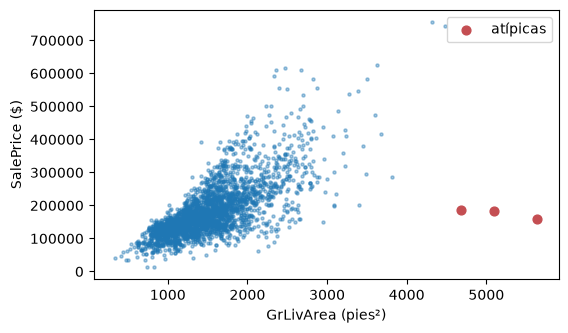

Casas restantes: 2927


In [12]:
atipicas = (casas["GrLivArea"] > 4000) & (casas["SalePrice"] < 300_000)
print(casas.loc[atipicas, ["GrLivArea", "SalePrice", "SaleCondition"]])

fig, eje = plt.subplots(figsize=(6, 3.5))
eje.scatter(casas["GrLivArea"], casas["SalePrice"], s=5, alpha=0.4)
eje.scatter(casas.loc[atipicas, "GrLivArea"], casas.loc[atipicas, "SalePrice"], s=40, color="#c44e52",
            label="atípicas")
eje.set(xlabel="GrLivArea (pies²)", ylabel="SalePrice ($)")
eje.legend()
plt.show()

casas = casas[~atipicas]
print("Casas restantes:", len(casas))
assert atipicas.sum() == 3 and len(casas) == 2927

## 9. Normalidad: transformación logarítmica

Cuando una variable positiva tiene una cola larga a la derecha, su logaritmo suele parecerse mucho más a una normal. Crear `LogPrecio` y `LogSuperficie` (de `GrLivArea`) y comparar antes y después la asimetría y el $r$ del gráfico de probabilidad, dibujando el histograma y el gráfico de probabilidad de las dos variables transformadas.

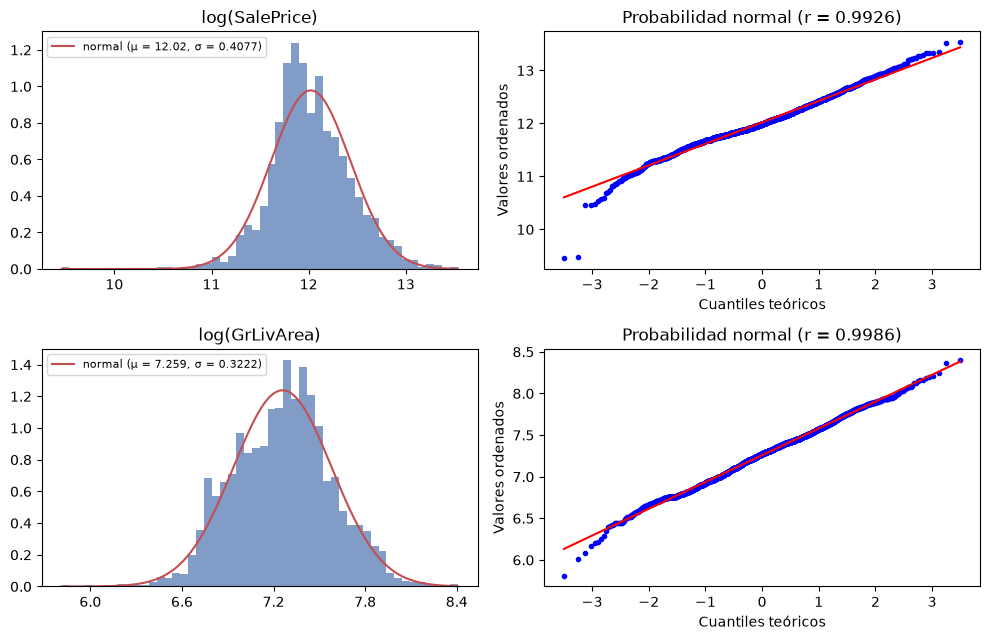

Variable        asimetría   → log
SalePrice           1.743  -0.014
GrLivArea           0.977  -0.037


In [13]:
casas = casas.assign(LogPrecio=np.log(casas["SalePrice"]), LogSuperficie=np.log(casas["GrLivArea"]))

fig, ejes = plt.subplots(2, 2, figsize=(10, 6.5))
r_log_precio = histograma_y_probabilidad(casas["LogPrecio"], "log(SalePrice)", ejes[0])
r_log_superficie = histograma_y_probabilidad(casas["LogSuperficie"], "log(GrLivArea)", ejes[1])
plt.tight_layout()
plt.show()

print(f"{'Variable':<14}{'asimetría':>11}{'→ log':>8}")
for original, transformada in [("SalePrice", "LogPrecio"), ("GrLivArea", "LogSuperficie")]:
    print(f"{original:<14}{casas[original].skew():11.3f}{casas[transformada].skew():8.3f}")
assert abs(casas["LogPrecio"].skew()) < abs(casas["SalePrice"].skew())
assert r_log_precio > r_precio

## 10. Una variable con ceros

El logaritmo de 0 no existe, y `TotalBsmtSF` vale 0 en las casas sin sótano. Crear una variable binaria `TieneSotano` (1 si la superficie es positiva) y aplicar el logaritmo solo a las casas que tienen sótano, dejando 0 en las demás. Comparar la asimetría de las superficies positivas antes y después y dibujar ambos histogramas.

TieneSotano
con sótano    2847
sin sótano      80
Asimetría de las superficies positivas: 0.852 → -0.488


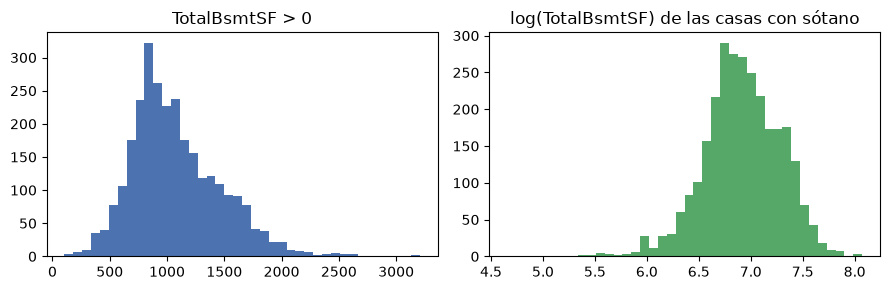

In [14]:
casas["TieneSotano"] = (casas["TotalBsmtSF"] > 0).astype(int)
con_sotano = casas["TieneSotano"] == 1
casas["LogSotano"] = 0.0
casas.loc[con_sotano, "LogSotano"] = np.log(casas.loc[con_sotano, "TotalBsmtSF"])

print(casas["TieneSotano"].value_counts().rename({1: "con sótano", 0: "sin sótano"}).to_string())
positivas = casas.loc[con_sotano, "TotalBsmtSF"]
print(f"Asimetría de las superficies positivas: {positivas.skew():.3f} → {np.log(positivas).skew():.3f}")

fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
ejes[0].hist(positivas, bins=40, color="#4c72b0")
ejes[0].set_title("TotalBsmtSF > 0")
ejes[1].hist(casas.loc[con_sotano, "LogSotano"], bins=40, color="#55a868")
ejes[1].set_title("log(TotalBsmtSF) de las casas con sótano")
plt.tight_layout()
plt.show()
assert np.isfinite(casas["LogSotano"]).all() and (casas.loc[~con_sotano, "LogSotano"] == 0).all()

## 11. Homocedasticidad

Hay homocedasticidad cuando la dispersión de una variable es parecida para todos los valores de otra. En la nube precio-superficie, los precios se abren en abanico a medida que crece la superficie; tras los logaritmos, la nube tiene un ancho más uniforme. Dibujar las dos nubes y medirlo: repartir las casas en cinco grupos del mismo tamaño según la superficie con `qcut` y comparar la desviación típica del precio (y del log-precio) en cada grupo, dividida entre la menor de las cinco.

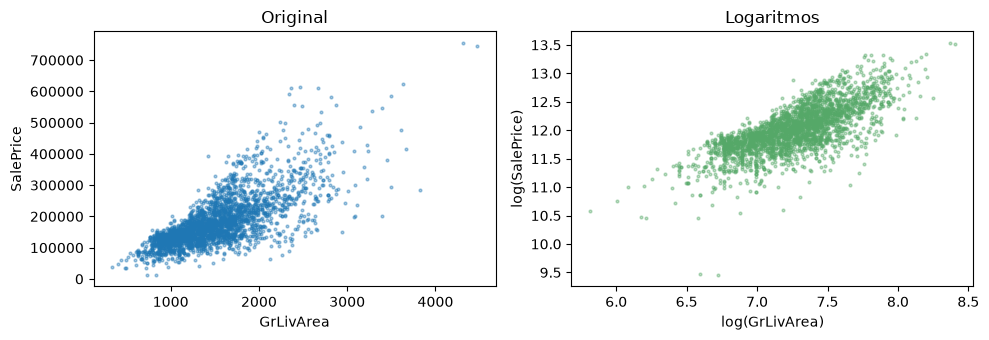

                   SalePrice  LogPrecio
GrLivArea                              
(333.999, 1064.2]       1.00       1.16
(1064.2, 1326.4]        1.23       1.00
(1326.4, 1559.6]        1.59       1.00
(1559.6, 1837.8]        2.25       1.19
(1837.8, 4476.0]        3.71       1.47
Cociente mayor/menor: {'SalePrice': 3.71, 'LogPrecio': 1.47}


In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
ejes[0].scatter(casas["GrLivArea"], casas["SalePrice"], s=4, alpha=0.4)
ejes[0].set(xlabel="GrLivArea", ylabel="SalePrice", title="Original")
ejes[1].scatter(casas["LogSuperficie"], casas["LogPrecio"], s=4, alpha=0.4, color="#55a868")
ejes[1].set(xlabel="log(GrLivArea)", ylabel="log(SalePrice)", title="Logaritmos")
plt.tight_layout()
plt.show()

grupos = pd.qcut(casas["GrLivArea"], 5)
desviaciones = pd.DataFrame({
    "SalePrice": casas.groupby(grupos, observed=True)["SalePrice"].std(),
    "LogPrecio": casas.groupby(grupos, observed=True)["LogPrecio"].std(),
})
relativas = desviaciones / desviaciones.min()
print(relativas.round(2))
print("Cociente mayor/menor:", relativas.max().round(2).to_dict())
assert relativas["LogPrecio"].max() < relativas["SalePrice"].max()

## 12. Variables dummy

Los modelos numéricos no entienden categorías de texto. Convertir `MSSubClass` en texto, porque sus números son códigos del tipo de vivienda y no cantidades, y transformar todas las columnas de texto en variables dummy (una columna 0/1 por categoría) con `pd.get_dummies(..., drop_first=True)`, que quita la primera categoría de cada variable porque se deduce de las demás. Comprobar que el número de columnas nuevas es la suma de (categorías − 1).

In [16]:
casas["MSSubClass"] = casas["MSSubClass"].astype(str)
categoricas = casas.select_dtypes(exclude="number").columns
print("Columnas de texto:", len(categoricas), "| ejemplo:", casas["CentralAir"].unique().tolist())

modelo = pd.get_dummies(casas, columns=categoricas, drop_first=True, dtype=int)
print("Antes:", casas.shape, "→ después:", modelo.shape)
print(modelo.filter(like="CentralAir").head(3))

esperadas = casas.shape[1] - len(categoricas) + sum(casas[c].nunique() - 1 for c in categoricas)
assert modelo.shape == (len(casas), esperadas)
assert modelo.select_dtypes(exclude="number").empty

Columnas de texto: 38 | ejemplo: ['Y', 'N']
Antes: (2927, 76) → después: (2927, 267)
           CentralAir_Y
PID                    
526301100             1
526350040             1
526351010             1
